# EDA Project: What Drives House Prices in Ames, Iowa?

**Dataset:** House Prices: Advanced Regression Techniques (Kaggle), file `train.csv`
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Jupyter Notebook
**Scope:** exploratory analysis only, no machine learning

## 1. Introduction

**Objective.** I want to find out which things push a house's sale price up or down, using nothing fancier than summary numbers, plots and a few sanity checks. The second goal is to practise the whole EDA workflow, from the raw file to a final story.

**Dataset.** Every row is one house sold in Ames, Iowa between 2006 and 2010. There are 1,460 rows and 81 columns covering size, quality, age, location and extras like the garage, basement and pool. The column I care about most is `SalePrice`.

**Questions this notebook tries to answer**

1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does overall quality (`OverallQual`) change the price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

## 2. Data loading (Step 1)

Starting simple. I import the libraries, set a clean plot style, load `train.csv` and check how big it is and what the first rows look like.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 100)

df = pd.read_csv("train.csv")
print("shape:", df.shape)
df.head()

shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**What I learned:** 1,460 rows and 81 columns, which matches the project brief. The first rows are a mix of numbers (areas, years, counts) and short text codes like `RL`, `Pave` and `Reg`.

`info()` shows the column names, data types and non-null counts in one go.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

**What I learned:** 38 columns are numeric and 43 are text. Some columns have non-null counts well below 1,460, so there is missing data to look at.

Now the missing values properly, worst first, with percentages.

In [3]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_table = pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df) * 100).round(2),
})
print("columns with missing values:", len(missing_table))
missing_table

columns with missing values: 19


,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


**Step 1 note**

- Rows: 1,460. Columns: 81.
- Columns with missing values: 19.
- First impressions: `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%) and `Fence` (80.8%) are almost empty. `MasVnrType` has 872 gaps (about 60%), which looks strange for a veneer column. `LotFrontage` is the only numeric column with a big gap (259 rows, 17.7%).
- Something I noticed: the garage columns all have exactly 81 missing and the basement columns have 37 or 38. Related columns sharing the same count doesn't look like random gaps. I'll check this in the cleaning section before I trust it.

## 3. Data understanding (Steps 2 and 3)

### Step 2: classifying the variables

I split the columns into numerical and categorical. The project also asks me to turn `ExterQual` and `KitchenQual` into ordered categories (Po < Fa < TA < Gd < Ex), so I do that here, then build a summary table for all 81 columns.

In [4]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
print("numeric columns:", len(numeric_cols))
print("categorical columns:", len(categorical_cols))

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}
for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

print("ExterQual order:", list(df["ExterQual"].cat.categories), "| ordered:", df["ExterQual"].cat.ordered)

numeric columns: 38
categorical columns: 43
ExterQual order: ['Po', 'Fa', 'TA', 'Gd', 'Ex'] | ordered: True


In [5]:
def var_type(col):
    if col in ordinal_map or col in ["OverallQual", "OverallCond"]:
        return "ordinal"
    if col == "MSSubClass":
        return "categorical (stored as number)"
    if col in numeric_cols:
        if "Yr" in col or "Year" in col or df[col].nunique() < 25:
            return "numerical (discrete)"
        return "numerical (continuous)"
    return "categorical (nominal)"

summary = pd.DataFrame({
    "column": df.columns,
    "type": [var_type(c) for c in df.columns],
    "unique_values": [df[c].nunique() for c in df.columns],
    "examples": [", ".join(map(str, df[c].dropna().unique()[:3])) for c in df.columns],
})
print(summary["type"].value_counts())
summary

type
categorical (nominal)             41
numerical (discrete)              18
numerical (continuous)            17
ordinal                            4
categorical (stored as number)     1
Name: count, dtype: int64


,column,type,unique_values,examples
0,Id,numerical (continuous),1460,"1, 2, 3"
1,MSSubClass,categorical (stored as number),15,"60, 20, 70"
2,MSZoning,categorical (nominal),5,"RL, RM, C (all)"
3,LotFrontage,numerical (continuous),110,"65.0, 80.0, 68.0"
4,LotArea,numerical (continuous),1073,"8450, 9600, 11250"
...,...,...,...,...
76,MoSold,numerical (discrete),12,"2, 5, 9"
77,YrSold,numerical (discrete),5,"2008, 2007, 2006"
78,SaleType,categorical (nominal),9,"WD, New, COD"
79,SaleCondition,categorical (nominal),6,"Normal, Abnorml, Partial"


**What I learned**

- `OverallQual` is stored as the numbers 1 to 10, but it is really ordinal. A jump from 4 to 5 is not necessarily the same size as a jump from 8 to 9. `OverallCond` has the same issue.
- `MSSubClass` is also stored as a number, but it is a dwelling-type code (20, 60, 120 and so on), so its average means nothing. It stays in the numeric list for the correlation work later, but its correlation with price is tiny (about -0.08), so it doesn't change any conclusion.
- The discrete vs continuous split is my own rule of thumb: year columns and anything with fewer than 25 unique values count as discrete.
- There are other text columns that are clearly ordinal (`BsmtQual`, `FireplaceQu`, `GarageQual` and so on). I only converted the two the project asks for.

### Step 3: descriptive statistics

First the overall `describe()` for every numeric column, just to see the ranges.

In [6]:
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


**What I learned:** `SalePrice` runs from 34,900 to 755,000. `LotArea` is the wild one: the median lot is about 9,500 sq ft but the biggest is 215,245. A lot of columns (`PoolArea`, `3SsnPorch`, `LowQualFinSF`, `MiscVal`) have a median of 0 because most houses simply don't have that feature.

Now the detailed numbers for the three columns the project names: `SalePrice`, `GrLivArea` and `LotArea`.

In [7]:
rows = {}
for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    rows[col] = {
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode()[0],
        "std": s.std(),
        "variance": s.var(),
        "range": s.max() - s.min(),
        "iqr": q3 - q1,
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
    }
    if s.mean() > s.median():
        note = "right skewed"
    elif s.mean() < s.median():
        note = "left skewed"
    else:
        note = "roughly symmetric"
    print(f"{col}: mean {s.mean():,.1f} vs median {s.median():,.1f} -> {note}")

stats_table = pd.DataFrame(rows).round(2)
stats_table.apply(lambda col: col.map("{:,.2f}".format))

SalePrice: mean 180,921.2 vs median 163,000.0 -> right skewed
GrLivArea: mean 1,515.5 vs median 1,464.0 -> right skewed
LotArea: mean 10,516.8 vs median 9,478.5 -> right skewed


,SalePrice,GrLivArea,LotArea
mean,"180,921.20","1,515.46","10,516.83"
median,"163,000.00","1,464.00","9,478.50"
mode,"140,000.00",864.00,"7,200.00"
std,"79,442.50",525.48,"9,981.26"
variance,"6,311,111,264.30","276,129.63","99,625,649.65"
range,"720,100.00","5,308.00","213,945.00"
iqr,"84,025.00",647.25,"4,048.00"
skewness,1.88,1.37,12.21
kurtosis,6.54,4.90,203.24


**Interpretation (mean vs median of SalePrice):** the mean is about 180,921 and the median is 163,000, so the mean sits roughly 18,000 above the middle house. That happens when a small number of expensive houses drag the average up, which is what a right-skewed distribution looks like. The skewness of 1.88 and the kurtosis of 6.5 (heavy tails) say the same thing. So the median is the fairer "typical price" here.

`GrLivArea` is also right skewed (skewness 1.37) but much more mildly. `LotArea` is extreme (skewness 12.2, kurtosis 203): a handful of huge lots stretch the range to almost 214,000 sq ft while the middle half of the houses are within about 4,000 sq ft of each other.

For the two categorical columns, the value counts and the mode.

In [8]:
for col in ["Neighborhood", "HouseStyle"]:
    print(col)
    print(df[col].value_counts())
    print("mode:", df[col].mode()[0], "\n")

Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
mode: NAmes 

HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
mode: 1Story 



**What I learned:** `NAmes` is the most common neighborhood (225 houses, about 15%), then `CollgCr` (150) and `OldTown` (113). For house style, `1Story` is the mode with 726 houses, almost half the data, followed by `2Story` (445). The other styles are small (`2.5Fin` has only 8 houses), so anything I say about the rare styles will be shaky.

## 4. Data cleaning (Step 9)

The notebook plan says to run the cleaning early if it affects later steps, and it does. Filling the "None" values and the `LotFrontage` gaps changes what the correlations and plots are built on. So Step 9 goes here, and every decision is logged in a table at the end of the section.

**Duplicates first.**

In [9]:
dup_count = df.duplicated().sum()
print("duplicate rows:", dup_count)
print("Id column unique:", df["Id"].is_unique)

if dup_count > 0:
    df = df.drop_duplicates()
    print("new shape:", df.shape)

duplicate rows: 0
Id column unique: True


**What I learned:** no duplicate rows and every `Id` is unique, so nothing to remove.

**Inconsistent labels.** I check every text column for casing and whitespace problems (like `Gd` vs `gd` or a trailing space). I also compare `Exterior1st` and `Exterior2nd`, since both describe the same list of materials and should spell them the same way.

In [10]:
problems = []
for col in categorical_cols:
    vals = pd.Series(df[col].dropna().astype(str).unique())
    tidy = vals.str.strip().str.lower()
    if tidy.duplicated().any() or (vals != vals.str.strip()).any():
        problems.append(col)
print("columns with casing or whitespace problems:", problems)

ex1 = set(df["Exterior1st"].unique())
ex2 = set(df["Exterior2nd"].unique())
print("only in Exterior1st:", sorted(ex1 - ex2))
print("only in Exterior2nd:", sorted(ex2 - ex1))

columns with casing or whitespace problems: []
only in Exterior1st: ['BrkComm', 'CemntBd', 'WdShing']
only in Exterior2nd: ['Brk Cmn', 'CmentBd', 'Other', 'Wd Shng']


No casing or whitespace problems anywhere, but there is a real inconsistency: `Exterior2nd` spells three materials differently from `Exterior1st` (`Brk Cmn` vs `BrkComm`, `CmentBd` vs `CemntBd`, `Wd Shng` vs `WdShing`). I map them to the `Exterior1st` spellings. `Other` only exists in `Exterior2nd`, but it's a genuine category, so it stays.

In [11]:
fix_exterior = {"Brk Cmn": "BrkComm", "CmentBd": "CemntBd", "Wd Shng": "WdShing"}
df["Exterior2nd"] = df["Exterior2nd"].replace(fix_exterior)

ex1 = set(df["Exterior1st"].unique())
ex2 = set(df["Exterior2nd"].unique())
print("only in Exterior2nd after the fix:", sorted(ex2 - ex1))

only in Exterior2nd after the fix: ['Other']


**Impossible values.** A few simple logic checks: sold before it was built, remodelled before it was built, garage built after the sale, and negative areas.

In [12]:
print("built after it was sold:", (df["YearBuilt"] > df["YrSold"]).sum())
print("remodelled before it was built:", (df["YearRemodAdd"] < df["YearBuilt"]).sum())
print("garage built after the sale:", (df["GarageYrBlt"] > df["YrSold"]).sum())

area_cols = [c for c in df.columns if "SF" in c or "Area" in c]
print("negative areas:", (df[area_cols] < 0).sum().sum())
print("YearBuilt range:", df["YearBuilt"].min(), "-", df["YearBuilt"].max())
print("YrSold range:", df["YrSold"].min(), "-", df["YrSold"].max())

built after it was sold: 0
remodelled before it was built: 0
garage built after the sale: 0
negative areas: 0
YearBuilt range: 1872 - 2010
YrSold range: 2006 - 2010


**What I learned:** all the checks come back as zero and the year ranges look sensible. Nothing impossible in this file.

**Are the missing values real?** This is the big question from Step 1. For each suspicious column I compare the number of gaps with a second column that tells me whether the feature exists at all (pool area, garage area, basement size, number of fireplaces).

In [13]:
checks = {
    "PoolQC": df["PoolArea"] == 0,
    "GarageType": df["GarageArea"] == 0,
    "BsmtQual": df["TotalBsmtSF"] == 0,
    "FireplaceQu": df["Fireplaces"] == 0,
}
for col, no_feature in checks.items():
    print(f"{col}: {df[col].isnull().sum()} missing | {no_feature.sum()} houses without that feature")

# what does the raw file actually say for MasVnrType?
raw = pd.read_csv("train.csv", keep_default_na=False)
print()
print(raw["MasVnrType"].value_counts())

PoolQC: 1453 missing | 1453 houses without that feature
GarageType: 81 missing | 81 houses without that feature
BsmtQual: 37 missing | 37 houses without that feature
FireplaceQu: 690 missing | 690 houses without that feature

MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NA           8
Name: count, dtype: int64


**What I learned:** the counts match exactly. All 1,453 missing `PoolQC` values are houses with `PoolArea` of 0, the 81 missing `GarageType` values are the 81 houses with no garage, the 37 missing `BsmtQual` values are the 37 houses with no basement, and the 690 missing `FireplaceQu` values are the 690 houses with no fireplace. So `NA` in these columns is a label meaning "no such feature". Pandas turns the text `NA` into a missing value by default, which is why they look like gaps.

`MasVnrType` is the same story in a different costume. Reading the raw file without the default NA handling shows 864 houses literally have the text `None` (no veneer) and only 8 are really `NA`.

So most of the "missing" data is not missing, and dropping those columns or rows would throw away real information.

**Filling.** For the "feature absent" columns I use the label `None`. Two basement columns (`BsmtExposure` and `BsmtFinType2`) need care, because one house in each has a basement but a real gap. For those I only write `None` where there is no basement and fill the one leftover with the most common value.

In [14]:
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtFinType1", "MasVnrType"]
for col in none_cols:
    df[col] = df[col].fillna("None")

for col in ["BsmtExposure", "BsmtFinType2"]:
    no_bsmt = df["TotalBsmtSF"] == 0
    df.loc[no_bsmt, col] = df.loc[no_bsmt, col].fillna("None")
    df[col] = df[col].fillna(df[col].mode()[0])

print("remaining missing in these columns:", df[none_cols + ["BsmtExposure", "BsmtFinType2"]].isnull().sum().sum())

remaining missing in these columns: 0


**The remaining gaps.** `LotFrontage` (259 rows) is a real gap. Lot shapes are fairly similar inside a neighborhood, so I fill it with the median of that neighborhood rather than the median of the whole column. `MasVnrArea` has 8 gaps on exactly the same rows where `MasVnrType` was `NA`, so I set them to 0 (no veneer). `Electrical` has one gap, which I fill with the most common type. `GarageYrBlt` has 81 gaps, but these are just the houses without a garage, and the column is strongly tied to `YearBuilt` anyway, so I drop it instead of inventing years.

In [15]:
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))

print("GarageYrBlt vs YearBuilt correlation:", round(df["GarageYrBlt"].corr(df["YearBuilt"]), 2))
df = df.drop(columns="GarageYrBlt")

print("missing values left:", df.isnull().sum().sum())
print("shape:", df.shape)

# refresh the numeric list (no Id, GarageYrBlt is gone)
numeric_cols = [c for c in df.select_dtypes(include="number").columns if c != "Id"]
print("numeric columns for analysis:", len(numeric_cols))

GarageYrBlt vs YearBuilt correlation: 0.83
missing values left: 0
shape: (1460, 80)
numeric columns for analysis: 36


**What I learned:** zero missing values left and the table has 1,460 rows and 80 columns. I also took `Id` out of the numeric list from here on, because it is only a row label.

**Cleaning log** (each decision, so it can be checked later)

| Column(s) | Problem | What I did | Why |
|---|---|---|---|
| Duplicates | none found | nothing | no duplicate rows, `Id` is unique |
| `Exterior2nd` | three spellings differ from `Exterior1st` | renamed to match | same materials, same labels |
| `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `BsmtQual`, `BsmtCond`, `BsmtFinType1` | `NA` means the feature doesn't exist | filled with `None` | gap counts match the "no feature" counts exactly |
| `BsmtExposure`, `BsmtFinType2` | same, plus one real gap each | `None` if no basement, otherwise the most common value | the two leftover gaps are houses that do have a basement |
| `MasVnrType`, `MasVnrArea` | `None` read as missing, plus 8 real gaps | `None` and 0 | no veneer is the most sensible reading |
| `Electrical` | 1 real gap | most common type | a single row, low risk |
| `LotFrontage` | 259 real gaps | median of the same neighborhood | lot layout is similar within a neighborhood |
| `GarageYrBlt` | 81 gaps (no garage) | dropped | repeats `YearBuilt` (correlation 0.83) and the gaps are not real unknowns |

## 5. Univariate analysis (Step 4)

### Question 1: the shape of SalePrice

Three plots side by side: histogram with a KDE curve, a boxplot, and a histogram of `log(SalePrice)`. Then I compare the skewness before and after the log.

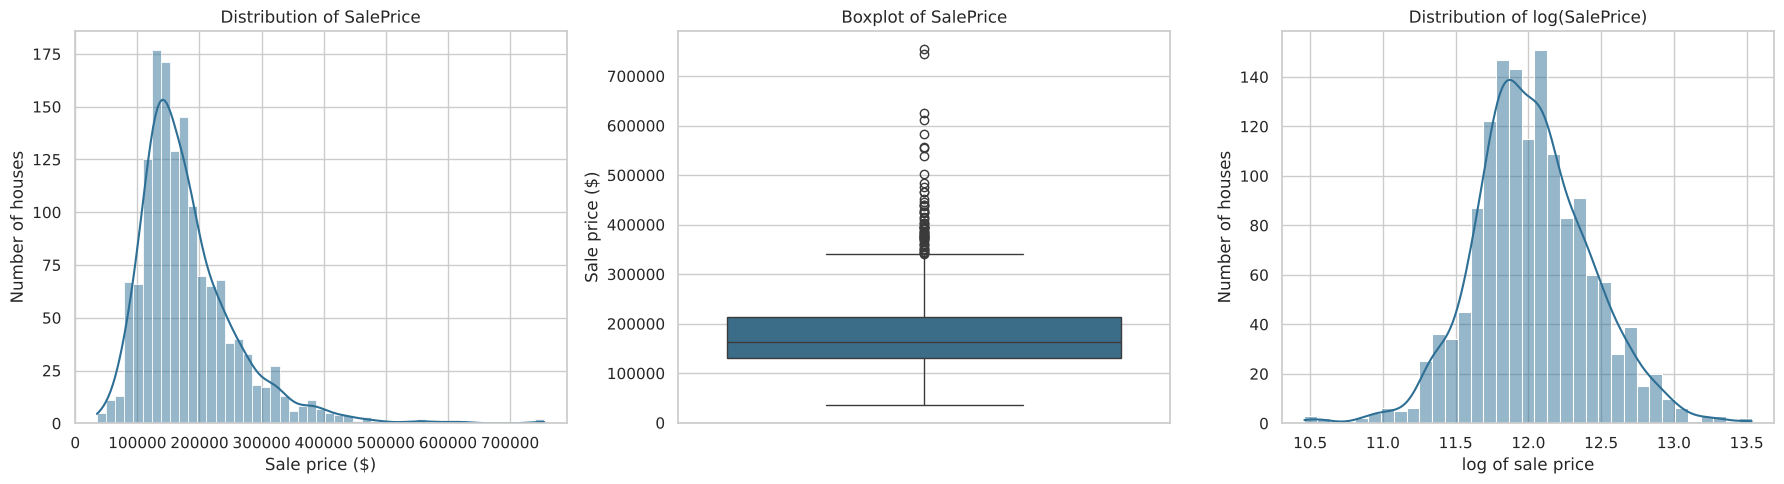

skewness before log: 1.883
skewness after log:  0.121


In [16]:
main = "#2E6F95"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color=main)
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale price ($)")
axes[0].set_ylabel("Number of houses")

sns.boxplot(y=df["SalePrice"], ax=axes[1], color=main)
axes[1].set_title("Boxplot of SalePrice")
axes[1].set_ylabel("Sale price ($)")

sns.histplot(np.log(df["SalePrice"]), kde=True, ax=axes[2], color=main)
axes[2].set_title("Distribution of log(SalePrice)")
axes[2].set_xlabel("log of sale price")
axes[2].set_ylabel("Number of houses")

plt.tight_layout()
plt.show()

print("skewness before log:", round(df["SalePrice"].skew(), 3))
print("skewness after log: ", round(np.log(df["SalePrice"]).skew(), 3))

**What I learned:** `SalePrice` has a long tail to the right. Most houses sell between roughly 100,000 and 250,000, but nine go past 500,000, and the boxplot has a string of dots above the upper whisker and none below. Skewness drops from 1.88 to 0.12 after taking the log, so the log version is close to symmetric. The histogram of the log is bell-shaped, though a bit peaked in the middle with a small tail of cheap houses on the left, so I'd say "close to normal" and not "normal". If this were ever used for modelling, the log price would be the better target.

### Question 3: price by overall quality

A boxplot of `SalePrice` for each quality score, plus the median and spread behind it.

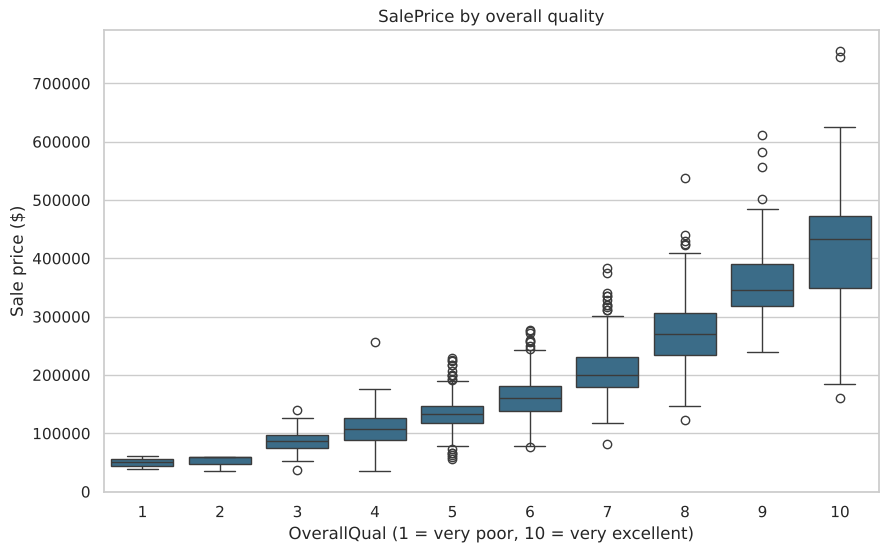

,count,median,std
OverallQual,,,
1,2,50150.0,15344.0
2,3,60000.0,14254.0
3,20,86250.0,24689.0
4,116,108000.0,29022.0
5,397,133000.0,27107.0
6,374,160000.0,36090.0
7,319,200141.0,44466.0
8,168,269750.0,63899.0
9,43,345000.0,81278.0


In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(x="OverallQual", y="SalePrice", data=df, color=main)
plt.title("SalePrice by overall quality")
plt.xlabel("OverallQual (1 = very poor, 10 = very excellent)")
plt.ylabel("Sale price ($)")
plt.show()

df.groupby("OverallQual")["SalePrice"].agg(["count", "median", "std"]).round(0)

**What I learned:** the median price goes up at every single step, from about 50,000 at quality 1 to about 432,000 at quality 10, and it never dips. The boxes also get taller as quality rises: the standard deviation is around 15,000 at quality 1 and about 160,000 at quality 10. So price rises in a clear, ordered way, and top-quality houses vary far more in price than low-quality ones. The left side is thin though (only 2 houses at quality 1 and 3 at quality 2).

### Question 4: price by neighborhood

Boxplot per neighborhood, sorted by median price, with the labels rotated so they fit.

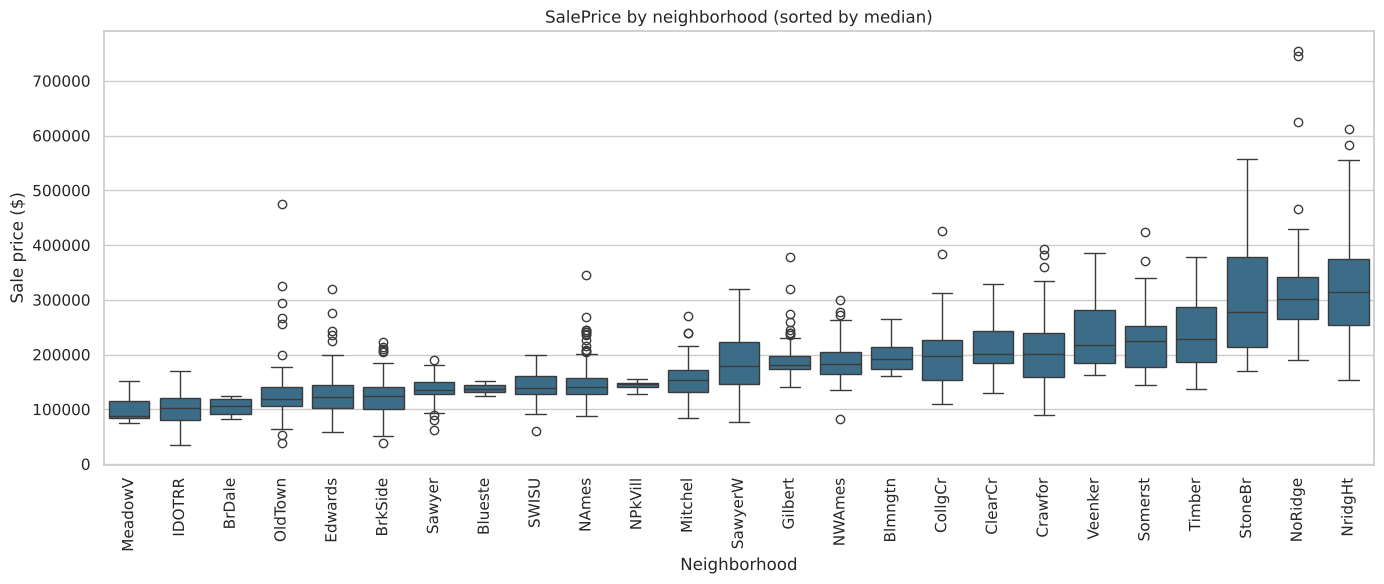

cheapest three (median):
Neighborhood
MeadowV     88000.0
IDOTRR     103000.0
BrDale     106000.0
Name: SalePrice, dtype: float64

most expensive three (median):
Neighborhood
StoneBr    278000.0
NoRidge    301500.0
NridgHt    315000.0
Name: SalePrice, dtype: float64

neighborhoods with the fewest sales:
Neighborhood
Veenker    11
NPkVill     9
Blueste     2
Name: count, dtype: int64


In [18]:
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(14, 6))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order, color=main)
plt.xticks(rotation=90)
plt.title("SalePrice by neighborhood (sorted by median)")
plt.xlabel("Neighborhood")
plt.ylabel("Sale price ($)")
plt.tight_layout()
plt.show()

med = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
print("cheapest three (median):")
print(med.head(3))
print("\nmost expensive three (median):")
print(med.tail(3))
print("\nneighborhoods with the fewest sales:")
print(df["Neighborhood"].value_counts().tail(3))

**What I learned:** neighborhood medians range from 88,000 (`MeadowV`) to 315,000 (`NridgHt`), a gap of about 3.6 times. `NridgHt`, `NoRidge` and `StoneBr` form a clear top group (medians of 315,000, 301,500 and 278,000), well above the next one, `Timber`, at about 228,000. At the bottom are `MeadowV`, `IDOTRR` and `BrDale`. So yes, some neighborhoods are consistently more expensive. One caution: a few neighborhoods have very few sales (`Blueste` has only 2), so their boxes shouldn't be trusted too much.

Two countplots to see how the houses are spread over quality and style.

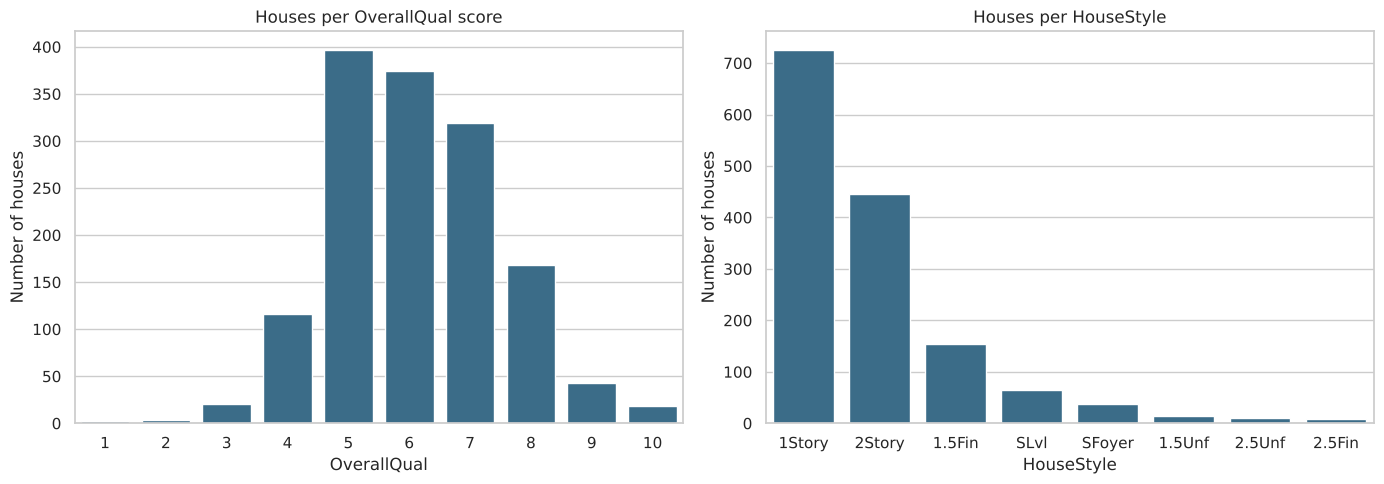

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="OverallQual", data=df, ax=axes[0], color=main)
axes[0].set_title("Houses per OverallQual score")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("Number of houses")

style_order = df["HouseStyle"].value_counts().index
sns.countplot(x="HouseStyle", data=df, ax=axes[1], order=style_order, color=main)
axes[1].set_title("Houses per HouseStyle")
axes[1].set_xlabel("HouseStyle")
axes[1].set_ylabel("Number of houses")

plt.tight_layout()
plt.show()

**What I learned:** most houses are middling. Quality 5 and 6 together cover over half the data (397 and 374 houses), while quality 1, 2 and 10 have 2, 3 and 18 houses. One-story and two-story houses dominate the styles. So the typical house in this data is an average one, and whatever I say about the extremes rests on few houses.

## 6. Bivariate and multivariate analysis (Steps 5, 6, 7)

### Step 5: correlation and covariance (Question 2)

I build the covariance and Pearson correlation matrices for the numeric columns, list the 10 features most correlated with `SalePrice`, and look at covariance next to correlation for the top 3.

In [20]:
cov_matrix = df[numeric_cols].cov()
corr_matrix = df[numeric_cols].corr()

top_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)
top10 = top_corr.head(10).index.tolist()

print("top 10 features by correlation with SalePrice:")
print(corr_matrix.loc[top10, "SalePrice"].round(3))

print()
for col in top10[:3]:
    cov_value = cov_matrix.loc[col, "SalePrice"]
    corr_value = corr_matrix.loc[col, "SalePrice"]
    print(f"{col}: covariance = {cov_value:,.0f}, correlation = {corr_value:.3f}")

top 10 features by correlation with SalePrice:
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

OverallQual: covariance = 86,904, correlation = 0.791
GrLivArea: covariance = 29,581,867, correlation = 0.709
GarageCars: covariance = 38,020, correlation = 0.640


**What I learned:** all ten correlations are positive. `OverallQual` (0.79) and `GrLivArea` (0.71) lead, followed by garage size (`GarageCars` 0.64, `GarageArea` 0.62), basement and first-floor size (`TotalBsmtSF` 0.61, `1stFlrSF` 0.61), then `FullBath`, `TotRmsAbvGrd`, `YearBuilt` and `YearRemodAdd` (0.51 to 0.56). In short, quality and size matter most, and age comes after.

**Why correlation is easier to compare than covariance:** covariance depends on the units of both columns. The covariance with `OverallQual` is about 86,900 (quality points times dollars), with `GrLivArea` it's about 29.6 million (square feet times dollars) and with `GarageCars` about 38,000 (cars times dollars). Those numbers are not comparable, and `GrLivArea` looks huge only because square feet are big numbers. Correlation divides by both standard deviations, so it has no units and always sits between -1 and 1. That is why I can say `OverallQual` (0.79) is more tightly linked to price than `GarageCars` (0.64).

*Optional step:* Spearman correlation for the ordinal columns. Pearson assumes a straight-line relationship with evenly spaced values, which isn't guaranteed for rating scales, and Spearman only uses the ranking.

In [21]:
ordinal_codes = pd.DataFrame({
    "OverallQual": df["OverallQual"],
    "ExterQual": df["ExterQual"].cat.codes,
    "KitchenQual": df["KitchenQual"].cat.codes,
})

for col in ordinal_codes.columns:
    rho, p_value = stats.spearmanr(ordinal_codes[col], df["SalePrice"])
    pearson = ordinal_codes[col].corr(df["SalePrice"])
    print(f"{col}: spearman = {rho:.3f} | pearson = {pearson:.3f}")

OverallQual: spearman = 0.810 | pearson = 0.791
ExterQual: spearman = 0.684 | pearson = 0.683
KitchenQual: spearman = 0.673 | pearson = 0.660


**What I learned:** `OverallQual` has a Spearman of 0.81, a bit above its Pearson of 0.79. `ExterQual` (0.68) and `KitchenQual` (0.67) are also clearly related to price. The numeric top 10 missed both of them completely because they are text columns, which is a good reminder that the top-10 list is not the full picture.

Now a look at which of the top features are correlated with each other, as the project asks.

In [22]:
pairs = [("GarageArea", "GarageCars"),
         ("1stFlrSF", "TotalBsmtSF"),
         ("GrLivArea", "TotRmsAbvGrd")]
for a, b in pairs:
    print(f"{a} vs {b}: {df[a].corr(df[b]):.3f}")

GarageArea vs GarageCars: 0.882
1stFlrSF vs TotalBsmtSF: 0.820
GrLivArea vs TotRmsAbvGrd: 0.825


**Interpretation (correlated features):** `GarageArea` and `GarageCars` have a correlation of 0.88, and `GrLivArea` with `TotRmsAbvGrd` (0.83) and `1stFlrSF` with `TotalBsmtSF` (0.82) are close behind. This matters for three reasons.

- The top-10 list partly repeats itself. Two garage columns measure basically the same thing (more cars means more area), so "ten strong features" is really fewer independent ideas: size, quality, age.
- If I put both into a model later, I couldn't tell which one is doing the work, and the coefficients would be unstable (multicollinearity).
- Correlation is not causation. Adding a car space doesn't by itself add the price. Bigger and nicer houses tend to have bigger garages, and both are tied to size and quality.

### Step 6: scatter plots and pair plots (Question 5, first look)

`GrLivArea` against `SalePrice`, with the houses over 4,000 sq ft that sold cheaply highlighted and labelled.

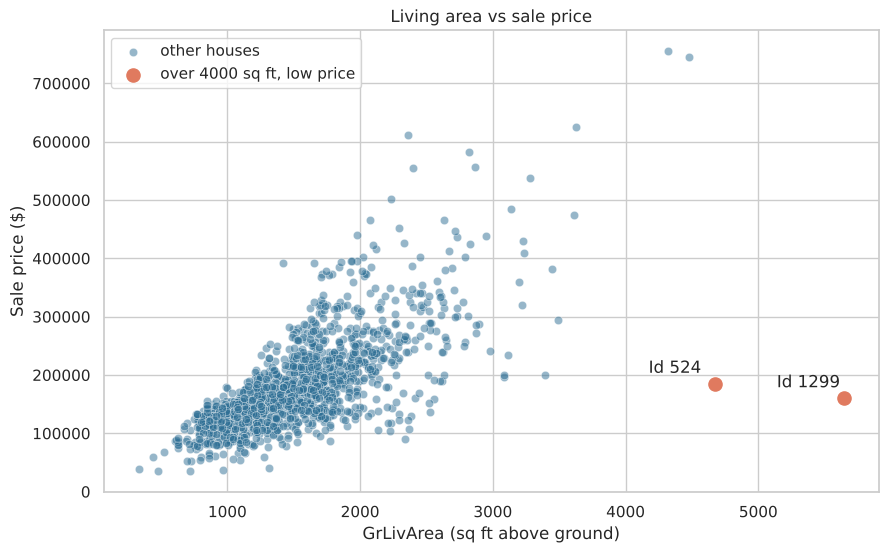

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition,Neighborhood
523,524,4676,184750,10,Partial,Edwards
691,692,4316,755000,10,Normal,NoRidge
1182,1183,4476,745000,10,Abnorml,NoRidge
1298,1299,5642,160000,10,Partial,Edwards


In [23]:
big_cheap = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)

plt.figure(figsize=(10, 6))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, alpha=0.5, color=main, label="other houses")
plt.scatter(df.loc[big_cheap, "GrLivArea"], df.loc[big_cheap, "SalePrice"],
            color="#E07A5F", s=90, label="over 4000 sq ft, low price")
for _, row in df[big_cheap].iterrows():
    plt.annotate(f"Id {int(row['Id'])}", (row["GrLivArea"], row["SalePrice"]),
                 textcoords="offset points", xytext=(-48, 8))
plt.title("Living area vs sale price")
plt.xlabel("GrLivArea (sq ft above ground)")
plt.ylabel("Sale price ($)")
plt.legend()
plt.show()

df.loc[df["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition", "Neighborhood"]]

**What I learned:** there's a clear upward trend, bigger houses cost more. Four houses are over 4,000 sq ft. Two of them (Id 692 and Id 1183) sold for about 755,000 and 745,000, which fits the trend. The other two (Id 524 and Id 1299, with 4,676 and 5,642 sq ft) sold for only 184,750 and 160,000, way below the trend. Those two are the suspicious ones. I come back to them in the outlier section.

Two more scatter plots: `TotalBsmtSF` and `YearBuilt` against `SalePrice`.

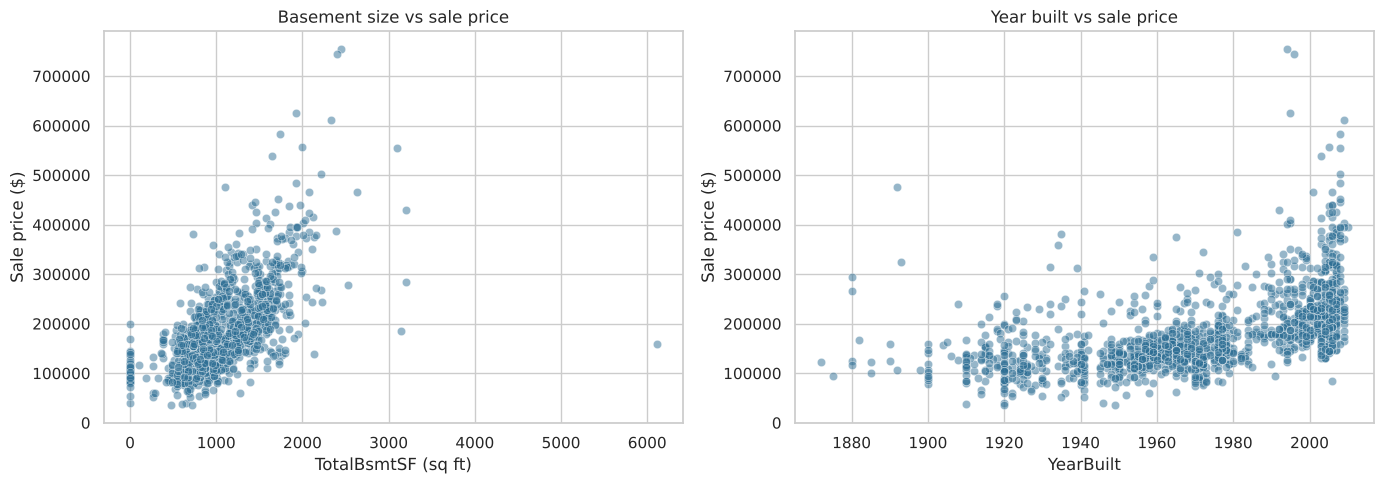

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df, alpha=0.5, color=main, ax=axes[0])
axes[0].set_title("Basement size vs sale price")
axes[0].set_xlabel("TotalBsmtSF (sq ft)")
axes[0].set_ylabel("Sale price ($)")

sns.scatterplot(x="YearBuilt", y="SalePrice", data=df, alpha=0.5, color=main, ax=axes[1])
axes[1].set_title("Year built vs sale price")
axes[1].set_xlabel("YearBuilt")
axes[1].set_ylabel("Sale price ($)")

plt.tight_layout()
plt.show()

**What I learned:** both go up. For `TotalBsmtSF` the relationship is roughly a straight line, with a column of points at 0 (the 37 houses with no basement) and one enormous 6,110 sq ft basement (Id 1299, the same house as before) sitting far below the trend. For `YearBuilt`, prices are fairly flat for houses built before 1950 and climb after that, and the spread gets wider for newer houses.

The pair plot of five selected columns, with KDE curves on the diagonal.

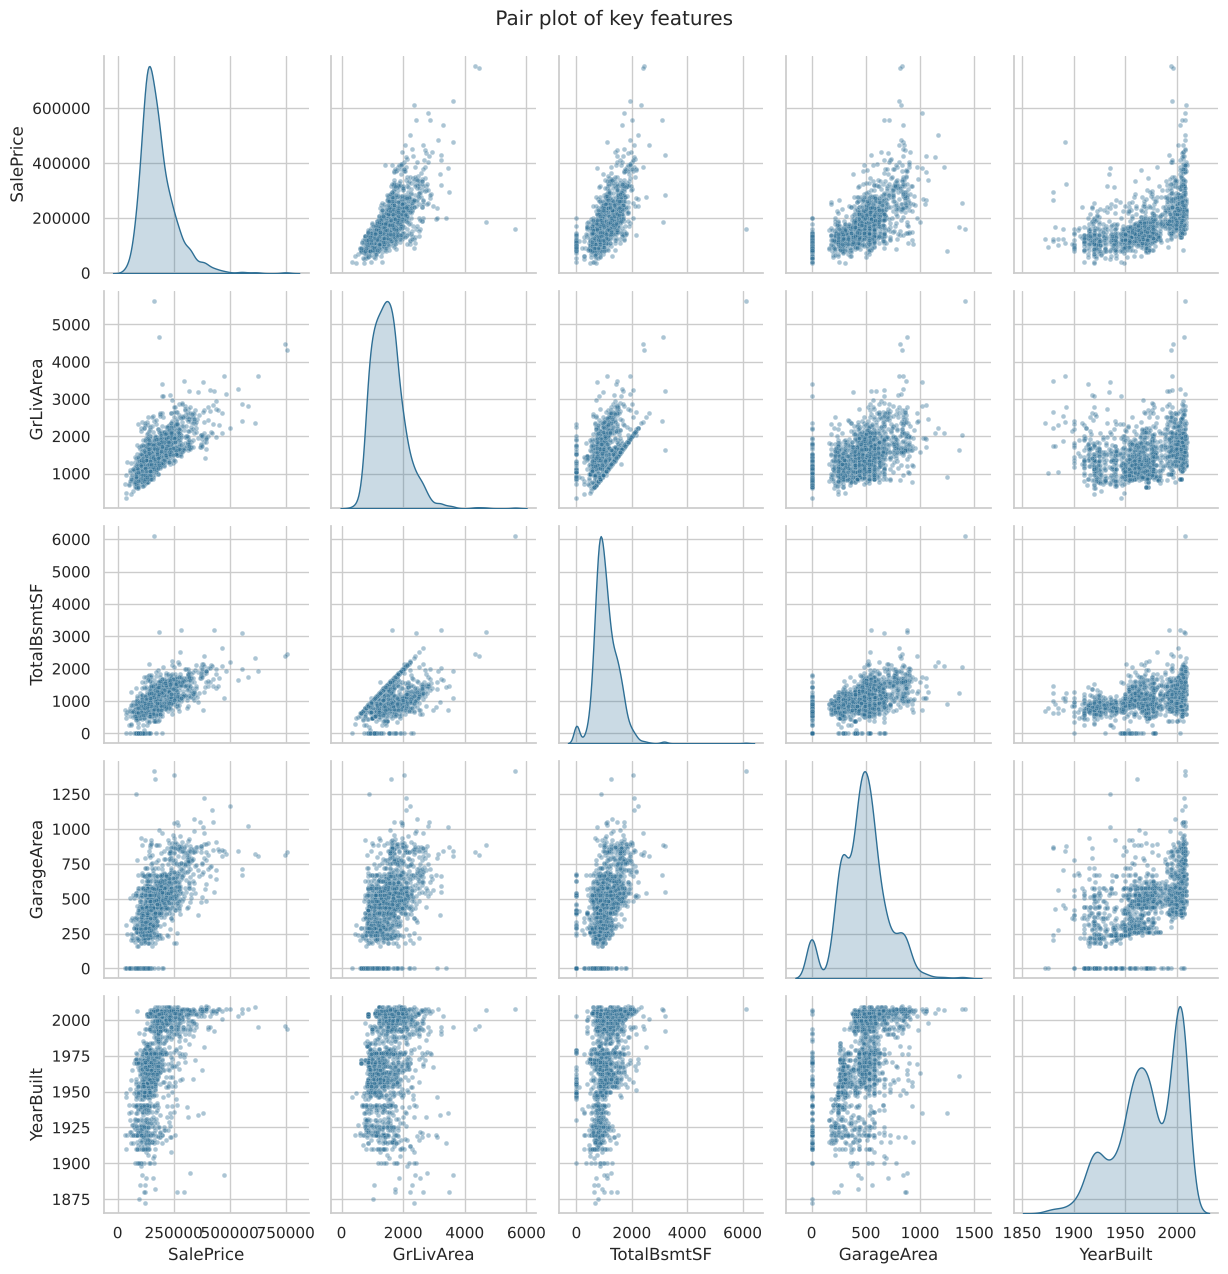

In [25]:
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]

g = sns.pairplot(df[selected], diag_kind="kde", plot_kws={"alpha": 0.4, "s": 12, "color": main},
                 diag_kws={"color": main})
g.fig.suptitle("Pair plot of key features", y=1.02)
plt.show()

**What I learned:** the diagonal curves show that `SalePrice`, `GrLivArea`, `TotalBsmtSF` and `GarageArea` are all right skewed, while `YearBuilt` leans the other way with a lump of recent houses. Most scatter panels are upward-sloping clouds that fan out at the high end, meaning that expensive houses vary more, which is another reason the log of the price behaves better. `GarageArea` has a vertical stack of points at 0 (no garage).

*Optional:* the same pair plot coloured by `CentralAir`.

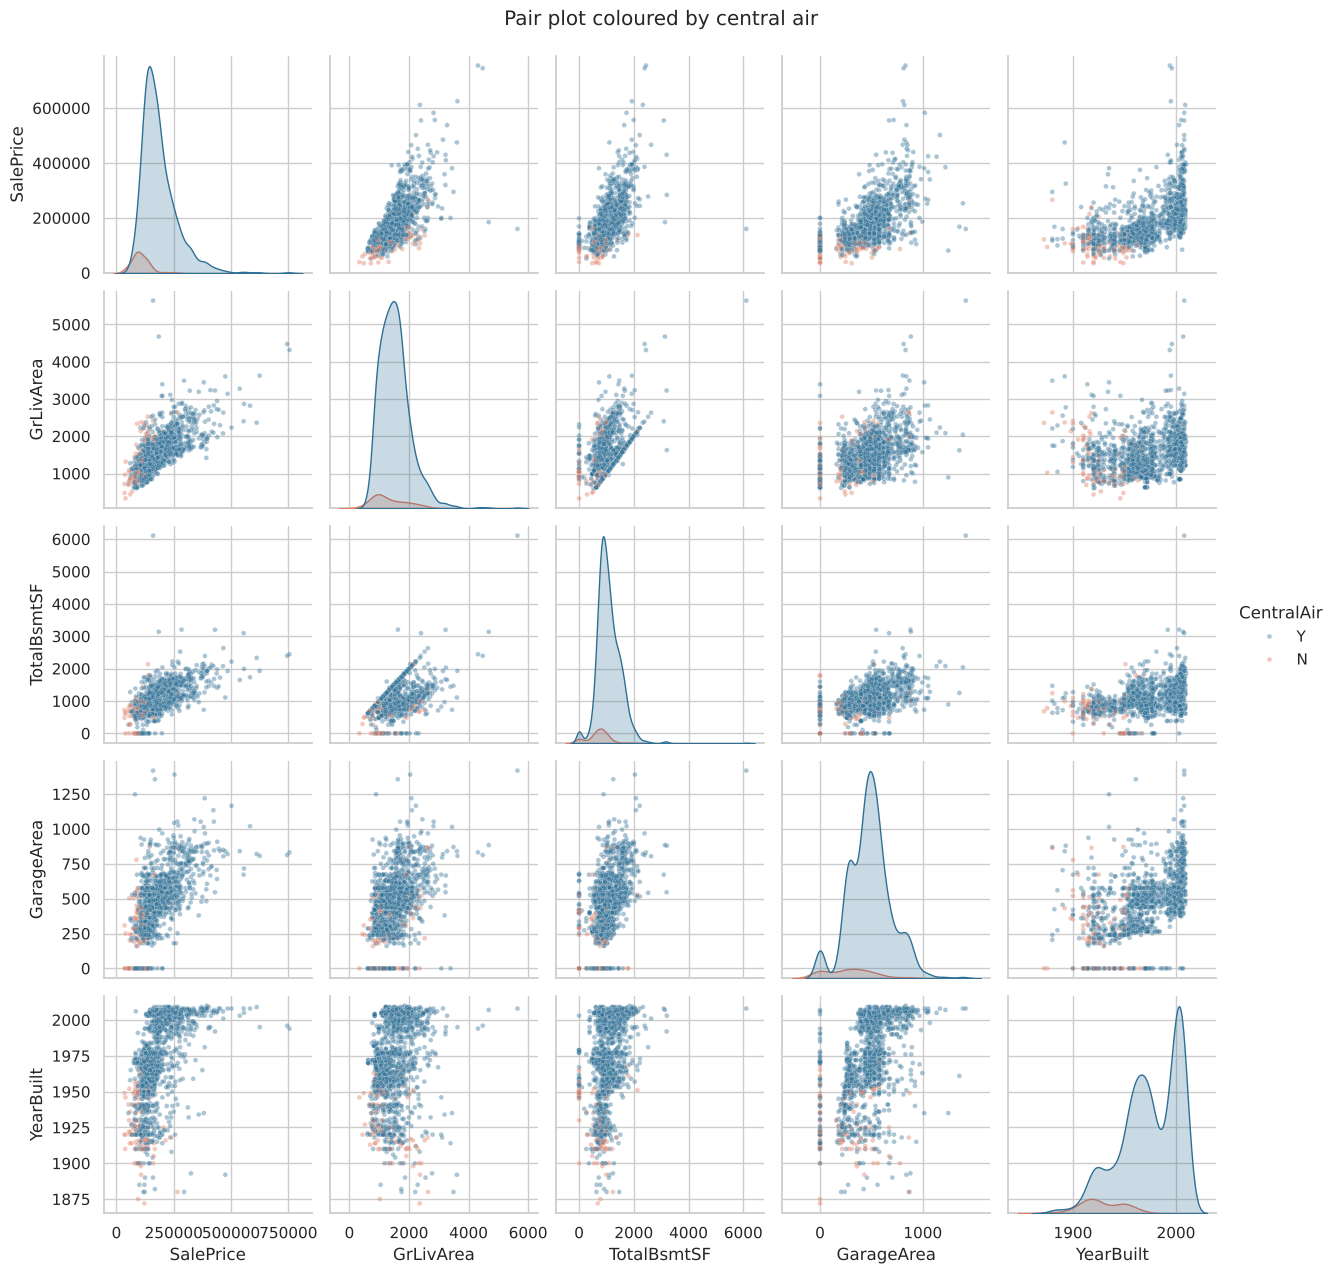

,count,median
CentralAir,,
N,95,98000.0
Y,1365,168000.0


In [26]:
g = sns.pairplot(df[selected + ["CentralAir"]], hue="CentralAir", diag_kind="kde",
                 plot_kws={"alpha": 0.4, "s": 12}, palette={"Y": main, "N": "#E07A5F"})
g.fig.suptitle("Pair plot coloured by central air", y=1.02)
plt.show()

df.groupby("CentralAir")["SalePrice"].agg(["count", "median"])

**What I learned:** the houses without central air (orange) sit in the low-price, low-size corner and are mostly old. The median price is 98,000 without central air and 168,000 with it, but only 95 houses have none, and no air also means older and smaller houses. So central air probably isn't "the reason" for the gap, it's a marker of the house's age and size.

### Step 7: correlation heatmap

One picture for the top 10 features plus `SalePrice`, showing only the lower half so nothing is repeated.

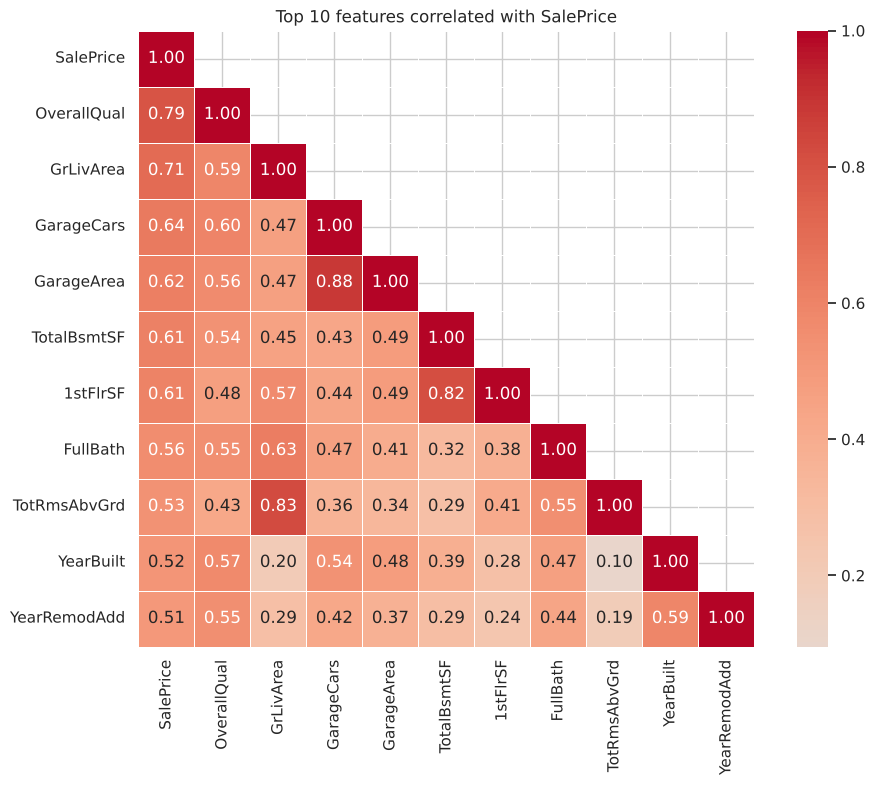

In [27]:
heat_cols = ["SalePrice"] + top10
corr_top = df[heat_cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            mask=mask, square=True, linewidths=0.5)
plt.title("Top 10 features correlated with SalePrice")
plt.show()

**What I learned:** the first row (`SalePrice`) is warm for every feature, with `OverallQual` and `GrLivArea` the strongest. Among the features themselves there are three warm blocks: the garage pair (0.88), the basement and first-floor pair (0.82) and the rooms and living-area pair (0.83). `YearBuilt` and `YearRemodAdd` are at 0.59, which makes sense because a house that was never remodelled has its remodel year set to its build year.

## 7. Outlier analysis (Step 8)

I flag outliers in two ways and compare them: the **IQR rule** (anything more than 1.5 IQR below Q1 or above Q3) and the **z-score rule** (more than 3 standard deviations from the mean). I run both on `GrLivArea` and `SalePrice`.

In [28]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

flagged = {}
for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])
    overlap = a.index.intersection(b.index)
    flagged[col] = (a, b)

    q1, q3 = df[col].quantile([0.25, 0.75])
    print(f"{col}: IQR flags {len(a)}, z-score flags {len(b)}, flagged by both {len(overlap)}")
    print(f"   IQR upper fence {q3 + 1.5 * (q3 - q1):,.0f} | z-score cutoff (mean + 3 std) {df[col].mean() + 3 * df[col].std():,.0f}")

GrLivArea: IQR flags 31, z-score flags 16, flagged by both 16
   IQR upper fence 2,748 | z-score cutoff (mean + 3 std) 3,092
SalePrice: IQR flags 61, z-score flags 22, flagged by both 22
   IQR upper fence 340,038 | z-score cutoff (mean + 3 std) 419,249


**What I learned:** for `GrLivArea` the IQR rule flags 31 houses and the z-score rule flags 16. For `SalePrice` it is 61 against 22. In both cases every z-score outlier is also an IQR outlier, but the IQR rule catches roughly twice as many or more.

**Interpretation (why z-score flags fewer on a skewed variable):** the z-score uses the mean and the standard deviation, and both are pulled by the very outliers I'm trying to find. In `SalePrice` the long right tail inflates the standard deviation (about 79,400) and lifts the mean (about 180,900), so the cutoff of mean + 3 std lands at around 419,000. The IQR rule is built from the quartiles, which the tail barely moves, so its upper fence is much closer to the bulk of the data, at about 340,000. On a right-skewed variable the z-score cutoff therefore moves far out and only the most extreme sales get past it, while the IQR fence also catches the moderately expensive ones.

To see what the two methods are flagging: boxplots with the outliers marked, then a scatter of `GrLivArea` against `SalePrice` with the flagged houses highlighted.

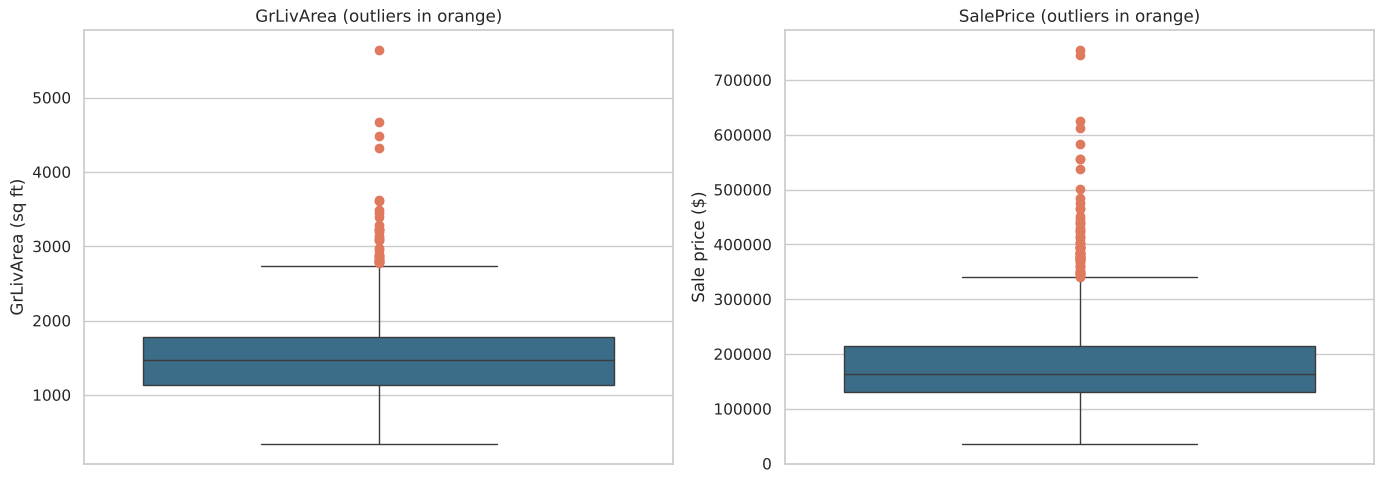

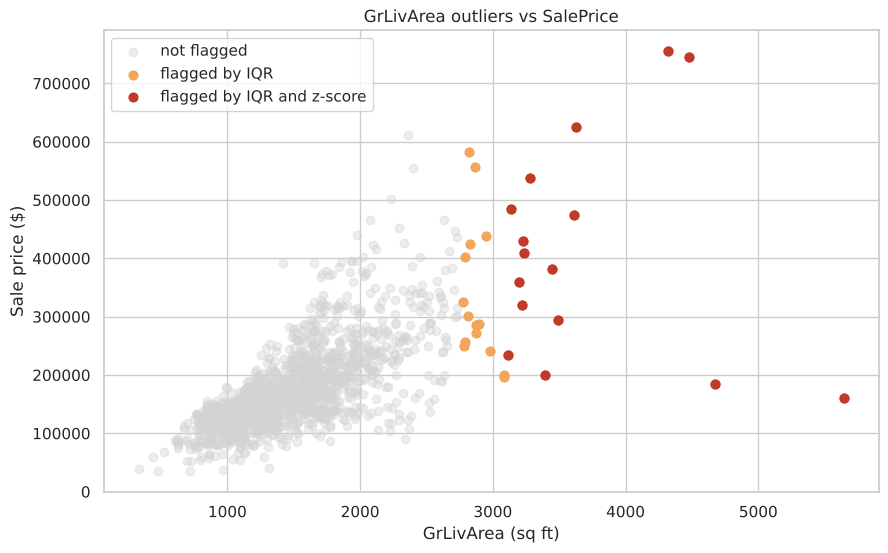

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
flier = {"markerfacecolor": "#E07A5F", "markeredgecolor": "#E07A5F"}

sns.boxplot(y=df["GrLivArea"], ax=axes[0], color=main, flierprops=flier)
axes[0].set_title("GrLivArea (outliers in orange)")
axes[0].set_ylabel("GrLivArea (sq ft)")

sns.boxplot(y=df["SalePrice"], ax=axes[1], color=main, flierprops=flier)
axes[1].set_title("SalePrice (outliers in orange)")
axes[1].set_ylabel("Sale price ($)")

plt.tight_layout()
plt.show()

iqr_idx = flagged["GrLivArea"][0].index
z_idx = flagged["GrLivArea"][1].index

plt.figure(figsize=(10, 6))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.4, color="lightgray", label="not flagged")
plt.scatter(df.loc[iqr_idx, "GrLivArea"], df.loc[iqr_idx, "SalePrice"],
            color="#F2A65A", s=40, label="flagged by IQR")
plt.scatter(df.loc[z_idx, "GrLivArea"], df.loc[z_idx, "SalePrice"],
            color="#C0392B", s=40, label="flagged by IQR and z-score")
plt.title("GrLivArea outliers vs SalePrice")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("Sale price ($)")
plt.legend()
plt.show()

**What I learned:** all the flagged values are on the high side, nothing falls below the lower fences. Most of the flagged points still follow the general trend, they're just big or expensive houses. Only the two at the bottom right (big but cheap) look out of place.

**Decision.** A flag is not proof of an error, so I look at the actual rows. I remove only houses that are over 4,000 sq ft **and** sold for less than 300,000, and keep everything else.

In [30]:
suspicious = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)
cols_to_show = ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition", "Neighborhood"]

print("houses I remove:")
print(df.loc[suspicious, cols_to_show])
print("\nother very large houses I keep:")
print(df.loc[(df["GrLivArea"] > 4000) & ~suspicious, cols_to_show])

df_clean = df[~suspicious].copy()
print("\ndf:", df.shape, "| df_clean:", df_clean.shape)

before = df["GrLivArea"].corr(df["SalePrice"])
after = df_clean["GrLivArea"].corr(df_clean["SalePrice"])
print(f"correlation of GrLivArea with SalePrice: {before:.3f} before, {after:.3f} after")

expensive = df[df["SalePrice"] > 340037.5]
print("\nOverallQual of the houses above the IQR upper fence for price:")
print(expensive["OverallQual"].value_counts().sort_index())

houses I remove:
        Id  GrLivArea  SalePrice  OverallQual SaleCondition Neighborhood
523    524       4676     184750           10       Partial      Edwards
1298  1299       5642     160000           10       Partial      Edwards

other very large houses I keep:
        Id  GrLivArea  SalePrice  OverallQual SaleCondition Neighborhood
691    692       4316     755000           10        Normal      NoRidge
1182  1183       4476     745000           10       Abnorml      NoRidge

df: (1460, 80) | df_clean: (1458, 80)
correlation of GrLivArea with SalePrice: 0.709 before, 0.735 after

OverallQual of the houses above the IQR upper fence for price:
OverallQual
7      3
8     22
9     23
10    13
Name: count, dtype: int64


**What I learned**

- The two houses I removed (Id 524 and Id 1299) are both quality 10 houses in `Edwards` with a `SaleCondition` of `Partial`, which means the home wasn't finished when it was assessed, mostly new builds. A price like 184,750 for a 4,676 sq ft quality-10 house doesn't look like the market value of the full house, so I treat them as non-typical sales.
- I keep the other two huge houses (Id 692 and Id 1183). They are in `NoRidge`, quality 10, and sold for around 750,000, which fits their size and quality. They're rare, not wrong.
- I also keep all the expensive-house outliers. Every house above the IQR fence for price has a quality of 7 or higher, and most are 8 to 10, so they're genuine high-end sales.
- Removing just two rows moves the correlation of `GrLivArea` with `SalePrice` from 0.709 to 0.735. Two odd sales were enough to pull the trend line noticeably down. `df_clean` has 1,458 rows and I use it for the dashboard.

## 8. Dashboard (Step 10)

Four panels in one figure, using `df_clean`: average price by year built, top 10 neighborhoods by average price, the price distribution with mean and median marked, and living area against price coloured by quality. One main blue with an orange accent runs through all panels, and the figure is saved as `eda_dashboard.png`.

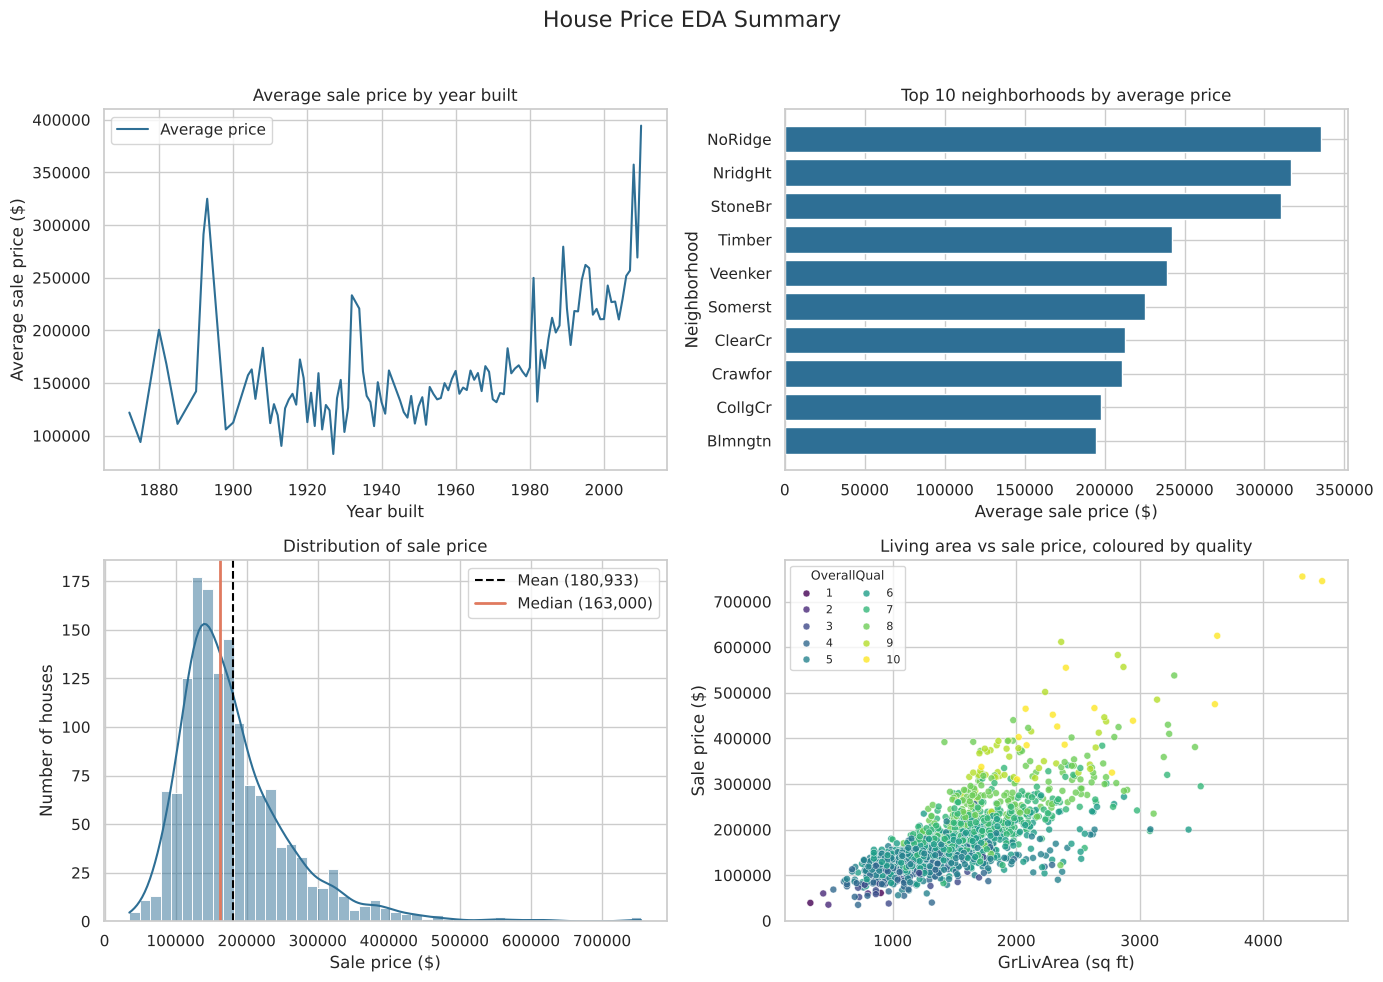

In [31]:
main = "#2E6F95"
accent = "#E07A5F"

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# panel 1: average price by year built
price_by_year = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(price_by_year.index, price_by_year.values, color=main, label="Average price")
axes[0, 0].set_title("Average sale price by year built")
axes[0, 0].set_xlabel("Year built")
axes[0, 0].set_ylabel("Average sale price ($)")
axes[0, 0].legend()

# panel 2: top 10 neighborhoods by average price
top_hoods = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=False).head(10)
axes[0, 1].barh(top_hoods.index[::-1], top_hoods.values[::-1], color=main)
axes[0, 1].set_title("Top 10 neighborhoods by average price")
axes[0, 1].set_xlabel("Average sale price ($)")
axes[0, 1].set_ylabel("Neighborhood")

# panel 3: distribution with mean and median
sns.histplot(df_clean["SalePrice"], kde=True, color=main, ax=axes[1, 0])
mean_price = df_clean["SalePrice"].mean()
median_price = df_clean["SalePrice"].median()
axes[1, 0].axvline(mean_price, color="black", linestyle="--", label=f"Mean ({mean_price:,.0f})")
axes[1, 0].axvline(median_price, color=accent, linestyle="-", linewidth=2, label=f"Median ({median_price:,.0f})")
axes[1, 0].set_title("Distribution of sale price")
axes[1, 0].set_xlabel("Sale price ($)")
axes[1, 0].set_ylabel("Number of houses")
axes[1, 0].legend()

# panel 4: living area vs price, coloured by quality
sns.scatterplot(data=df_clean, x="GrLivArea", y="SalePrice", hue="OverallQual",
                palette="viridis", s=25, alpha=0.8, legend="full", ax=axes[1, 1])
axes[1, 1].set_title("Living area vs sale price, coloured by quality")
axes[1, 1].set_xlabel("GrLivArea (sq ft)")
axes[1, 1].set_ylabel("Sale price ($)")
axes[1, 1].legend(title="OverallQual", fontsize=8, title_fontsize=9, ncol=2)

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()

**What the dashboard shows**

- For houses built before the mid-1970s the average mostly stays between 100,000 and 170,000, and it climbs clearly for newer ones. The line is jumpy in the early years because only a few houses were built in each of those years.
- The most expensive neighborhoods by average price are `NoRidge`, `NridgHt` and `StoneBr`, all above 300,000, which agrees with the medians from the boxplot.
- The mean is above the median, as expected for a right-skewed variable.
- In the scatter, price grows with living area and the colours stack by quality. For the same size, the darker (lower quality) points sit lower and the yellow-green (quality 8 to 10) points sit higher. So size and quality work together.

## 9. Conclusions

### Answers to the six questions

1. **Distribution.** `SalePrice` is right skewed (skewness 1.88, mean about 180,900 against a median of 163,000). Taking the log brings the skewness down to 0.12.
2. **Strongest correlates.** `OverallQual` (0.79) and `GrLivArea` (0.71) lead, then garage size (0.64 and 0.62) and basement and first-floor size (0.61 each). Quality and size matter most, age comes after.
3. **Quality.** Yes, the median rises at every quality level, from about 50,000 at 1 to about 432,000 at 10, and the spread is much larger at the top.
4. **Neighborhoods.** Yes. Medians run from 88,000 to 315,000, and `NridgHt`, `NoRidge` and `StoneBr` stand clearly above the rest.
5. **Outliers.** The IQR rule flags 61 prices and 31 living areas (the z-score rule flags 22 and 16). Most are real expensive or big houses and I kept them. Only two houses (Id 524 and Id 1299) looked like non-typical sales, and I removed them.
6. **Missing values.** 19 columns have gaps, but most are not really missing: `NA` means the house has no pool, alley, fence, fireplace, garage or basement. The truly missing values are 259 in `LotFrontage`, 8 in `MasVnrArea`, 1 in `Electrical` and two basement cells.

### Checking the expected insights

| Expected insight | What I found | Verdict |
|---|---|---|
| `SalePrice` is right skewed and the log makes it close to normal | skewness 1.88, then 0.12 after the log; the log histogram is bell-shaped, slightly peaked | Confirmed |
| `OverallQual` and `GrLivArea` are among the strongest correlates | they are #1 and #2 (0.79 and 0.71) | Confirmed |
| Price rises steadily with quality, with larger spread at the top | medians rise at every level; the standard deviation grows from about 15,000 to about 160,000 | Confirmed |
| A few neighborhoods have clearly higher medians | `NridgHt`, `NoRidge` and `StoneBr` | Confirmed |
| A handful of very large, low-priced houses are unusual sales that distort trend lines | two houses, both `Partial` sales; removing them lifts the correlation from 0.709 to 0.735 | Confirmed |
| Many apparent missing values are really "feature absent" | for example 1,453 `PoolQC` gaps match the 1,453 houses with no pool | Confirmed |

### Limitations

- The data is one city (Ames, Iowa) over 2006 to 2010, a period that includes the US housing downturn. The findings may not carry over to other places or years, and prices are not adjusted for market changes during those years.
- Correlation is not causation, and the Pearson correlation only picks up straight-line relationships. Many features overlap (garage, basement, living area), so I can't give each one its own share of the effect.
- Several cleaning choices were judgment calls: median by neighborhood for `LotFrontage`, `None` for absent features, dropping `GarageYrBlt`, and removing two houses. Different choices could change the numbers a little.
- I only treated two columns as properly ordinal, and I didn't compare most of the other categorical columns (like `SaleCondition` or `MSZoning`) against price at all.
- Some neighborhoods and house styles have very few houses, so their medians are not very reliable.
- This is descriptive work only. I didn't build a model, so nothing here says how well price could be predicted.